<a href="https://colab.research.google.com/github/xl4357/MSSP6070/blob/main/Assignments/Assignment02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import userdata
import os
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

github_token = userdata.get('Git_Key')

owner = 'xl4357'
repository = 'MSSP6070'
repo_path = f'/content/{repository}'

if not os.path.exists(repo_path):
    clone_url = (
        f'https://x-access-token:{github_token}'
        f'@github.com/{owner}/{repository}.git'
    )

    subprocess.run(
        ['git', 'clone', clone_url, repo_path],
        check=True
    )

os.chdir(repo_path)

print("Repository path:", os.getcwd())
print("Files:", os.listdir('.'))

Repository path: /content/MSSP6070
Files: ['Add_File_Structure.py', '.git', 'aapl.csv', 'amzn.csv', 'data', 'WeeklyModules', 'HW_Participation_Activity_Week1_Exercises.ipynb', 'goog.csv', 'nflx.csv', 'fb.csv', 'Assignments']


link to file

In [3]:
file_path = os.path.join(
    repo_path,
    'Assignments',
    'InternetSales.csv'
)

In [4]:
internet_sales = pd.read_csv(
    file_path,
    delimiter=',',
    parse_dates=[
        'BirthDate',
        'DateFirstPurchase',
        'OrderDate',
        'DueDate',
        'ShipDate'
    ],
    low_memory=False,
    index_col='ID',
    encoding='latin1'
)

print("Dataset shape:", internet_sales.shape)

internet_sales.head()

Dataset shape: (60398, 59)


,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,LastName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
ID,,,,,,,,,,,,,,,,,,,,,
0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,2011-01-19,2011-01-31,2011-01-26
1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,2013-01-18,2013-01-30,2013-01-25
3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,2013-05-03,2013-05-15,2013-05-10
4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,2013-05-03,2013-05-15,2013-05-10


What are the Internet sales of Adventure Works by year for each Country Region?

In [5]:
internet_sales = internet_sales.assign(
    orderyear=internet_sales['OrderDate'].dt.year
)

internet_sales[['OrderDate', 'orderyear',
                'EnglishCountryRegionName', 'SalesAmount']].head()

,OrderDate,orderyear,EnglishCountryRegionName,SalesAmount
ID,,,,
0,2011-01-19,2011,Australia,3399.99
1,2013-01-18,2013,Australia,2319.99
2,2013-01-18,2013,Australia,21.98
3,2013-05-03,2013,Australia,2384.07
4,2013-05-03,2013,Australia,28.99


Summarize Internet sales by year and country/region

In [6]:
sales_by_year_country = (
    internet_sales
    .groupby(
        ['orderyear', 'EnglishCountryRegionName'],
        as_index=False
    )
    .agg({'SalesAmount': 'sum'})
)

sales_by_year_country

,orderyear,EnglishCountryRegionName,SalesAmount
0,2010,Australia,2.090978e+04
1,2010,Canada,3.578270e+03
2,2010,France,3.399990e+03
3,2010,United Kingdom,6.990982e+02
4,2010,United States,1.483390e+04
5,2011,Australia,2.563732e+06
6,2011,Canada,5.715718e+05
7,2011,France,4.108453e+05
8,2011,Germany,5.205002e+05
9,2011,United Kingdom,5.505912e+05


In [7]:
sales_pivot = sales_by_year_country.pivot(
    index='orderyear',
    columns='EnglishCountryRegionName',
    values='SalesAmount'
)

sales_pivot_millions = sales_pivot / 1_000_000

sales_pivot_millions.round(3)

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
orderyear,,,,,,
2010,0.021,0.004,0.003,NaN,0.001,0.015
2011,2.564,0.572,0.411,0.521,0.551,2.458
2012,2.128,0.308,0.648,0.609,0.713,1.437
2013,4.339,1.086,1.579,1.762,2.124,5.462
2014,0.009,0.009,0.003,0.003,0.004,0.018


Plot annual Internet sales by country/region

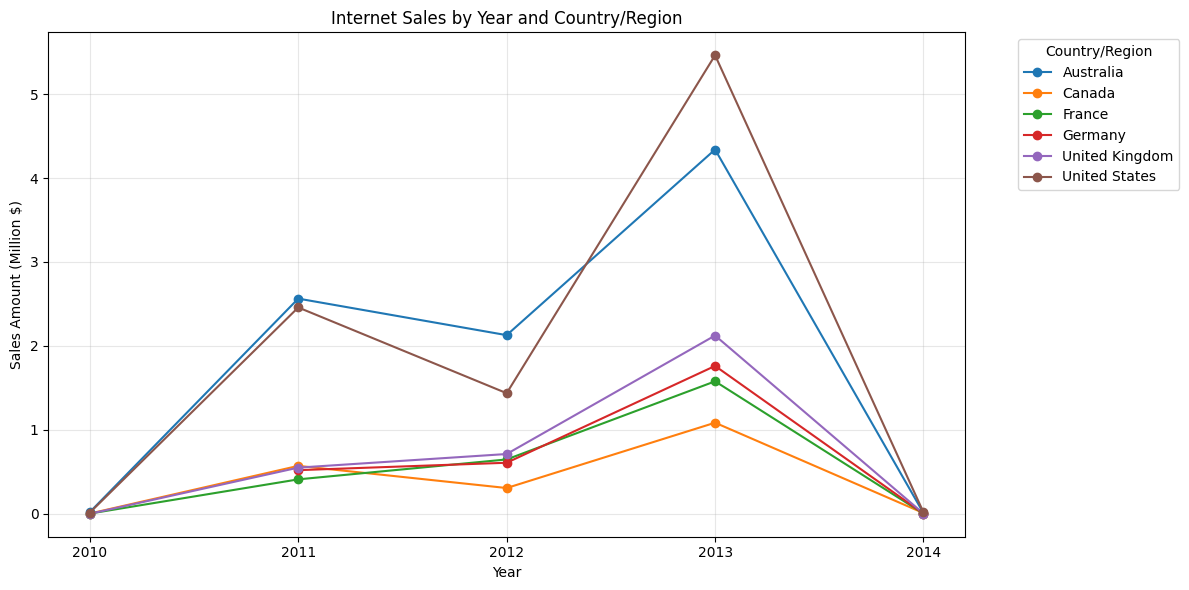

In [8]:
plt.figure(figsize=(12, 6))

for country in sales_pivot_millions.columns:
    plt.plot(
        sales_pivot_millions.index,
        sales_pivot_millions[country],
        marker='o',
        label=country
    )

plt.title('Internet Sales by Year and Country/Region')
plt.xlabel('Year')
plt.ylabel('Sales Amount (Million $)')
plt.xticks(sales_pivot_millions.index)
plt.legend(title='Country/Region', bbox_to_anchor=(1.05, 1),
           loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Calculate total Internet sales by country/region

In [9]:
country_sales = (
    internet_sales
    .groupby('EnglishCountryRegionName')['SalesAmount']
    .sum()
    .sort_values(ascending=False)
)

country_sales_millions = country_sales / 1_000_000

print("Total Internet Sales by Country/Region (Million $):")
print(country_sales_millions.round(3))

Total Internet Sales by Country/Region (Million $):
EnglishCountryRegionName
United States     9.390
Australia         9.061
United Kingdom    3.392
Germany           2.894
France            2.644
Canada            1.978
Name: SalesAmount, dtype: float64


Annual Sales Growth by Country/Region

In [10]:
annual_sales = sales_pivot_millions.loc[[2011, 2012, 2013]]

annual_sales.round(3)

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
orderyear,,,,,,
2011,2.564,0.572,0.411,0.521,0.551,2.458
2012,2.128,0.308,0.648,0.609,0.713,1.437
2013,4.339,1.086,1.579,1.762,2.124,5.462


In [11]:
sales_growth = annual_sales.pct_change(axis=0) * 100

sales_growth.round(2)

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
orderyear,,,,,,
2011,NaN,NaN,NaN,NaN,NaN,NaN
2012,-16.98,-46.18,57.74,16.94,29.44,-41.54
2013,103.88,252.93,143.57,189.47,198.02,280.09


Plot year-over-year sales growth by country/region

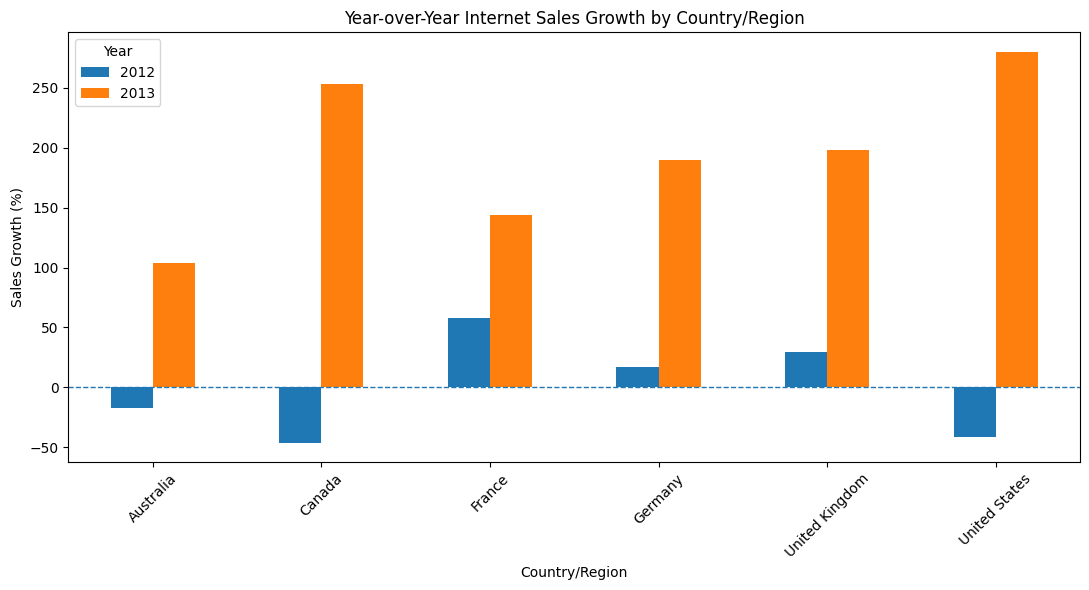

In [12]:

sales_growth.loc[[2012, 2013]].T.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Year-over-Year Internet Sales Growth by Country/Region')
plt.xlabel('Country/Region')
plt.ylabel('Sales Growth (%)')
plt.xticks(rotation=45)
plt.axhline(y=0, linestyle='--', linewidth=1)
plt.legend(title='Year')
plt.tight_layout()
plt.show()

In [13]:
fastest_growth = sales_growth.loc[[2012, 2013]].idxmax(axis=1)

highest_growth = sales_growth.loc[[2012, 2013]].max(axis=1)

growth_summary = pd.DataFrame({
    'Fastest Growing Region': fastest_growth,
    'Growth Rate (%)': highest_growth
})

growth_summary.round(2)

,Fastest Growing Region,Growth Rate (%)
orderyear,,
2012,France,57.74
2013,United States,280.09


Generate summary statistics including min, max, and standard deviation for Yearly Income, Gender by Country Regions.  

In [14]:
customer_profiles = internet_sales[
    [
        'CustomerKey',
        'EnglishCountryRegionName',
        'YearlyIncome',
        'Gender',
        'HouseOwnerFlag'
    ]
].drop_duplicates()

print("Number of unique customers:",
      customer_profiles['CustomerKey'].nunique())

print("Customer profile shape:",
      customer_profiles.shape)

customer_profiles.head()

Number of unique customers: 18484
Customer profile shape: (18484, 5)


,CustomerKey,EnglishCountryRegionName,YearlyIncome,Gender,HouseOwnerFlag
ID,,,,,
0,11000,Australia,90000,M,1
8,11001,Australia,60000,M,0
19,11002,Australia,60000,M,1
23,11003,Australia,70000,F,0
32,11004,Australia,80000,F,1


Calculate income statistics by country/region

In [15]:
income_summary = (
    customer_profiles
    .groupby('EnglishCountryRegionName')['YearlyIncome']
    .agg(['count', 'min', 'max', 'mean', 'std'])
    .round(2)
)

income_summary

,count,min,max,mean,std
EnglishCountryRegionName,,,,,
Australia,3591,10000,170000,64338.62,31830.00
Canada,1571,10000,170000,57167.41,20251.52
France,1810,10000,110000,35762.43,27277.40
Germany,1780,10000,130000,42943.82,35493.58
United Kingdom,1913,10000,170000,52169.37,48431.99
United States,7819,10000,170000,63616.83,25706.48


Count male and female customers by country/region

In [16]:
gender_counts = pd.crosstab(
    customer_profiles['EnglishCountryRegionName'],
    customer_profiles['Gender']
)

gender_counts

Gender,F,M
EnglishCountryRegionName,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


In [17]:
gender_percentage = pd.crosstab(
    customer_profiles['EnglishCountryRegionName'],
    customer_profiles['Gender'],
    normalize='index'
) * 100

gender_percentage.round(2)

Gender,F,M
EnglishCountryRegionName,,
Australia,49.48,50.52
Canada,48.82,51.18
France,49.34,50.66
Germany,49.10,50.90
United Kingdom,48.82,51.18
United States,49.73,50.27


Plot gender distribution by country/region

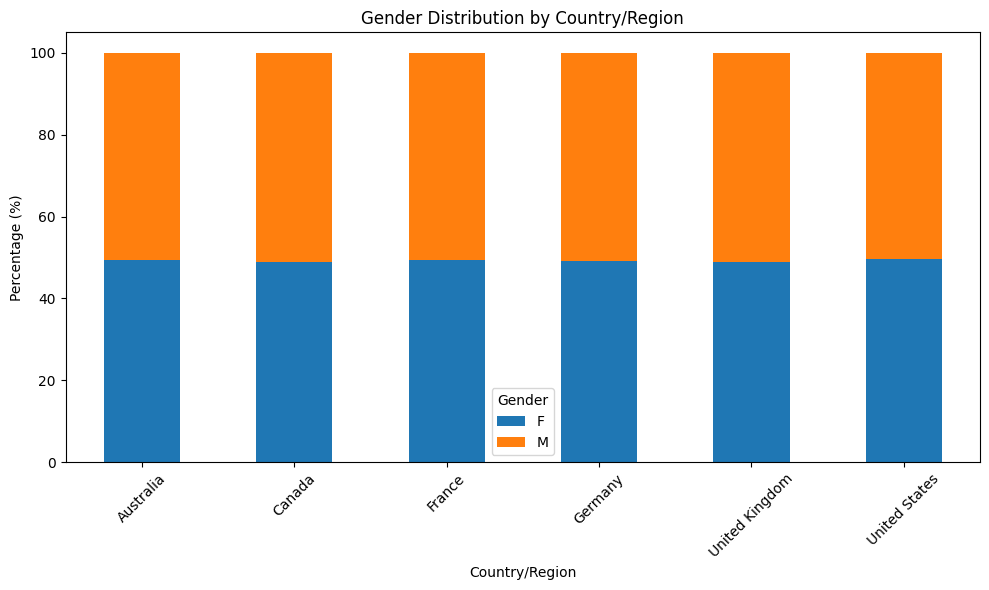

In [18]:
gender_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Gender Distribution by Country/Region')
plt.xlabel('Country/Region')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

Which product category generates the most sales, and what is its average price?

In [19]:
def classify_product(product_name):

    if product_name.startswith(
        ('Mountain-', 'Road-', 'Touring-')
    ):
        return 'Bikes'

    elif any(word in product_name for word in [
        'Jersey', 'Socks', 'Gloves',
        'Vest', 'Shorts'
    ]):
        return 'Clothing'

    elif any(word in product_name for word in [
        'Tire', 'Tube'
    ]):
        return 'Components'

    else:
        return 'Accessories'


internet_sales['ProductCategory'] = (
    internet_sales['EnglishProductName']
    .apply(classify_product)
)

internet_sales[
    ['EnglishProductName', 'ProductCategory']
].drop_duplicates().head(20)

,EnglishProductName,ProductCategory
ID,,
0,"Mountain-100 Silver, 38",Bikes
1,"Mountain-200 Silver, 38",Bikes
2,Fender Set - Mountain,Accessories
3,"Touring-1000 Blue, 46",Bikes
4,Touring Tire,Components
5,Touring Tire Tube,Components
6,"Sport-100 Helmet, Red",Accessories
7,"Short-Sleeve Classic Jersey, S",Clothing
10,Water Bottle - 30 oz.,Accessories


In [20]:
category_sales = (
    internet_sales
    .groupby('ProductCategory')
    .agg(
        TotalSales=('SalesAmount', 'sum'),
        NumberOfProducts=('ProductKey', 'nunique'),
        NumberOfSales=('SalesAmount', 'count')
    )
    .sort_values('TotalSales', ascending=False)
)

category_sales['TotalSales_Millions'] = (
    category_sales['TotalSales'] / 1000000
)

category_sales.round(2)

,TotalSales,NumberOfProducts,NumberOfSales,TotalSales_Millions
ProductCategory,,,,
Bikes,28318144.65,116,15205,28.32
Accessories,482226.13,13,24141,0.48
Clothing,320084.51,19,6911,0.32
Components,238221.93,10,14141,0.24


In [21]:
product_prices = (
    internet_sales[
        ['ProductKey', 'EnglishProductName',
         'ProductCategory', 'UnitPrice']
    ]
    .drop_duplicates(subset='ProductKey')
)

category_avg_price = (
    product_prices
    .groupby('ProductCategory')['UnitPrice']
    .mean()
)

print("Average product price by category:")
print(category_avg_price.round(2))

Average product price by category:
ProductCategory
Accessories      38.78
Bikes          1542.80
Clothing         47.78
Components       21.20
Name: UnitPrice, dtype: float64


In [22]:
transaction_avg_price = (
    internet_sales
    .groupby('ProductCategory')['UnitPrice']
    .mean()
)

print(transaction_avg_price.round(2))

ProductCategory
Accessories      19.98
Bikes          1862.42
Clothing         46.32
Components       16.85
Name: UnitPrice, dtype: float64


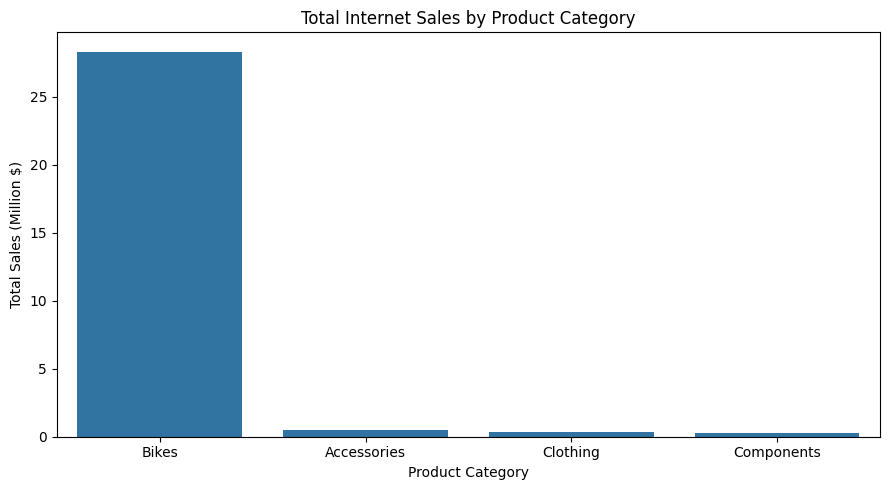

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_sales.reset_index(),
    x='ProductCategory',
    y='TotalSales_Millions'
)

plt.title('Total Internet Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales (Million $)')
plt.tight_layout()
plt.show()

Does owning a home make a difference in sales? Explain your analysis.

In [24]:
internet_sales['HouseOwnerFlag'].value_counts()

,count
HouseOwnerFlag,
1,41699
0,18699


In [25]:
customer_sales = (
    internet_sales
    .groupby(['CustomerKey', 'HouseOwnerFlag'])
    .agg(
        TotalSales=('SalesAmount', 'sum'),
        NumberOfOrders=('SalesOrderNumber', 'nunique')
    )
    .reset_index()
)

customer_sales.head()

,CustomerKey,HouseOwnerFlag,TotalSales,NumberOfOrders
0,11000,1,8248.99,3
1,11001,0,6383.88,3
2,11002,1,8114.04,3
3,11003,0,8139.29,3
4,11004,1,8196.01,3


In [26]:
home_sales_summary = (
    customer_sales
    .groupby('HouseOwnerFlag')
    .agg(
        NumberOfCustomers=('CustomerKey', 'nunique'),
        AverageCustomerSales=('TotalSales', 'mean'),
        MedianCustomerSales=('TotalSales', 'median'),
        TotalSales=('TotalSales', 'sum'),
        AverageOrders=('NumberOfOrders', 'mean')
    )
)

home_sales_summary.round(2)

,NumberOfCustomers,AverageCustomerSales,MedianCustomerSales,TotalSales,AverageOrders
HouseOwnerFlag,,,,,
0,5982,1500.05,209.96,8973327.42,1.44
1,12502,1630.57,342.00,20385349.80,1.52


In [27]:
home_sales_summary['CustomerShare'] = (
    home_sales_summary['NumberOfCustomers']
    / home_sales_summary['NumberOfCustomers'].sum()
    * 100
)

home_sales_summary['SalesShare'] = (
    home_sales_summary['TotalSales']
    / home_sales_summary['TotalSales'].sum()
    * 100
)

home_sales_summary.round(2)

,NumberOfCustomers,AverageCustomerSales,MedianCustomerSales,TotalSales,AverageOrders,CustomerShare,SalesShare
HouseOwnerFlag,,,,,,,
0,5982,1500.05,209.96,8973327.42,1.44,32.36,30.56
1,12502,1630.57,342.00,20385349.80,1.52,67.64,69.44


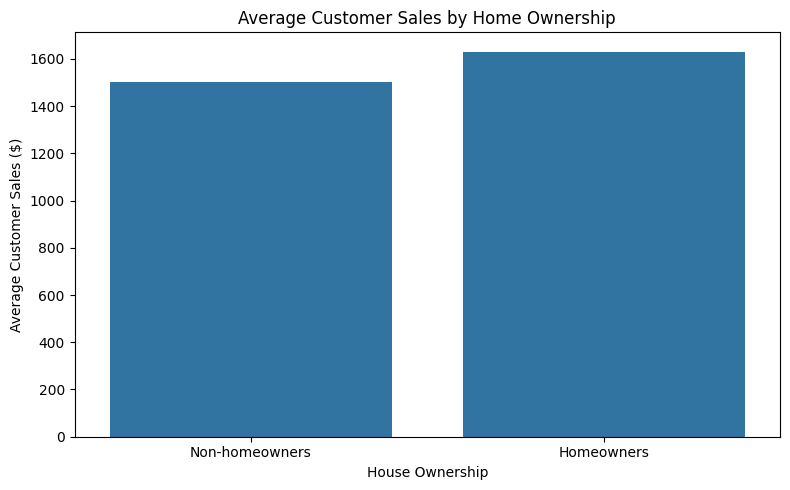

In [28]:
plot_data = home_sales_summary.reset_index()

plot_data['HouseOwnership'] = plot_data[
    'HouseOwnerFlag'
].map({
    0: 'Non-homeowners',
    1: 'Homeowners'
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_data,
    x='HouseOwnership',
    y='AverageCustomerSales'
)

plt.title('Average Customer Sales by Home Ownership')
plt.xlabel('House Ownership')
plt.ylabel('Average Customer Sales ($)')
plt.tight_layout()
plt.show()

In [29]:
from scipy.stats import ttest_ind

homeowners = customer_sales.loc[
    customer_sales['HouseOwnerFlag'] == 1,
    'TotalSales'
]

non_homeowners = customer_sales.loc[
    customer_sales['HouseOwnerFlag'] == 0,
    'TotalSales'
]

t_stat, p_value = ttest_ind(
    homeowners,
    non_homeowners,
    equal_var=False
)

print("T-statistic:", round(t_stat, 4))
print("P-value:", p_value)

T-statistic: 3.9838
P-value: 6.820263286221625e-05
